# Projeto de IA – Parte 3: Classificação de Filmes de Animação
**FATEC Rodrigues de Abreu – Bauru/SP**
Autores: João Victor Godoy Bortolotti e Raul Pavan
Orientadora: Profa. Dra. Patricia Bellin Ribeiro

Objetivo: classificar filmes de animação em **Bom (1, nota TMDB ≥ 7)** ou **Ruim (0, nota < 7)**
a partir de atributos numéricos, categóricos e textuais da base tratada na Parte 2.

Algoritmos: **Regressão Logística** e **Random Forest** (Scikit-Learn).

In [1]:
import json, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay)
warnings.filterwarnings('ignore')
SEED = 42
os.makedirs('figs', exist_ok=True)  # pasta usada pelos gráficos
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

## 1. Carregamento da base tratada (Parte 2)

In [2]:
df = pd.read_csv('CSV_Tratado_Projeto_IA_Parte2.csv')
print(df.shape)
print(df['Classe'].value_counts().rename({0: 'Ruim (0)', 1: 'Bom (1)'}))
print((df['Classe'].value_counts(normalize=True) * 100).round(2))

(16118, 45)
Classe
Ruim (0)    10642
Bom (1)      5476
Name: count, dtype: int64
Classe
0    66.03
1    33.97
Name: proportion, dtype: float64


## 2. Engenharia de atributos

Para evitar **vazamento de dados (data leakage)** foram descartadas colunas derivadas da nota
(`TMDB_Rating`, que define a classe, e `Hidden_Gem`, calculada a partir dela), além de
identificadores, URLs e colunas com mais de 85% de valores ausentes (orçamento, bilheteria, ROI).
Colunas de alta cardinalidade (estúdio, diretor, elenco) não foram usadas nesta fase.

In [3]:
df = df.copy()
df['Genre_txt'] = df['Genre'].fillna('').str.replace('|', ',', regex=False)
df['Overview'] = df['Overview'].fillna('')
df['Log_Vote_Count'] = np.log1p(df['TMDB_Vote_Count'])
df['Log_Popularity'] = np.log1p(df['TMDB_Popularity'])
df['Has_Collection'] = df['Belongs_To_Collection'].notna().astype(int)
df['Has_Budget'] = df['Budget_Million_USD'].notna().astype(int)
df['Has_Box_Office'] = df['Box_Office_Million_USD'].notna().astype(int)
df['Remake'] = (df['Live_Action_Remake'] == 'Yes').astype(int)
df['Target_Audience'] = df['Target_Audience'].str.replace('|', '/', regex=False)
top_lang = df['Original_Language'].value_counts().index[:15]
df['Lang'] = df['Original_Language'].where(df['Original_Language'].isin(top_lang), 'other')
mpaa_top = df['MPAA_Rating'].value_counts().index[:10]
df['MPAA'] = df['MPAA_Rating'].where(df['MPAA_Rating'].isin(mpaa_top), 'other')
for c in ['Is_TV_Compilation', 'Is_Adult_Content', 'Is_Future_Release']:
    df[c] = df[c].astype(int)

NUM = ['Release_Year', 'Movie_Length_Minutes', 'Log_Vote_Count', 'Log_Popularity',
       'Has_Collection', 'Has_Budget', 'Has_Box_Office', 'Remake',
       'Is_TV_Compilation', 'Is_Adult_Content', 'Is_Future_Release']
CAT = ['Animation_Style', 'Target_Audience', 'Lang', 'MPAA', 'Era', 'Popularity_Tier']
X = df[NUM + CAT + ['Genre_txt', 'Overview']]
y = df['Classe']
print(X.shape)

(16118, 19)


## 3. Divisão dos dados

Divisão **estratificada 80/20** (treino/teste): 80% garante volume suficiente para o
aprendizado (~12,9 mil filmes) e 20% (~3,2 mil) gera um teste estatisticamente estável;
a estratificação preserva a proporção 66/34 entre as classes. No conjunto de treino
aplica-se ainda **validação cruzada estratificada de 5 folds** para estimar a variância dos modelos.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
split_info = {'treino': len(X_train), 'teste': len(X_test),
              'bom_treino': float(y_train.mean()), 'bom_teste': float(y_test.mean())}
print(split_info)

{'treino': 12894, 'teste': 3224, 'bom_treino': 0.3397704358616411, 'bom_teste': 0.3396401985111663}


## 4. Pré-processamento em pipeline (sem vazamento entre treino e teste)

In [5]:
def make_preprocessor():
    num_pipe = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())])
    cat_pipe = Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                         ('ohe', OneHotEncoder(handle_unknown='ignore'))])
    return ColumnTransformer([
        ('num', num_pipe, NUM),
        ('cat', cat_pipe, CAT),
        ('genre', TfidfVectorizer(tokenizer=lambda s: [t.strip().lower() for t in s.split(',') if t.strip()],
                                  token_pattern=None, lowercase=False), 'Genre_txt'),
        ('ovw', TfidfVectorizer(max_features=3000, stop_words='english', ngram_range=(1, 2),
                                min_df=3, sublinear_tf=True), 'Overview'),
    ])

models = {
    'Baseline (classe majoritária)': DummyClassifier(strategy='most_frequent'),
    'Regressão Logística': LogisticRegression(C=1.0, class_weight='balanced',
                                              max_iter=2000, solver='liblinear', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                            class_weight='balanced_subsample',
                                            n_jobs=-1, random_state=SEED),
}
pipes = {n: Pipeline([('prep', make_preprocessor()), ('clf', m)]) for n, m in models.items()}

## 5. Validação cruzada (5 folds) no conjunto de treino

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
cv_results = {}
for name, pipe in pipes.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_results[name] = {m: (float(r['test_' + m].mean()), float(r['test_' + m].std())) for m in scoring}
cv_df = pd.DataFrame({n: {m: f'{v[0]:.3f} ± {v[1]:.3f}' for m, v in d.items()} for n, d in cv_results.items()}).T
cv_df

,accuracy,precision,recall,f1,roc_auc
Baseline (classe majoritária),0.660 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Regressão Logística,0.645 ± 0.005,0.482 ± 0.006,0.617 ± 0.017,0.541 ± 0.009,0.698 ± 0.007
Random Forest,0.705 ± 0.010,0.571 ± 0.016,0.535 ± 0.014,0.552 ± 0.014,0.745 ± 0.011


## 6. Treinamento final e avaliação no conjunto de teste

In [7]:
test_results, preds, probas = {}, {}, {}
for name, pipe in pipes.items():
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    pr = pipe.predict_proba(X_test)[:, 1]
    preds[name], probas[name] = p, pr
    test_results[name] = {
        'accuracy': accuracy_score(y_test, p),
        'precision': precision_score(y_test, p, zero_division=0),
        'recall': recall_score(y_test, p),
        'f1': f1_score(y_test, p),
        'roc_auc': roc_auc_score(y_test, pr),
        'cm': confusion_matrix(y_test, p).tolist(),
    }
    print(f'=== {name} ===')
    print(classification_report(y_test, p, target_names=['Ruim (0)', 'Bom (1)'], digits=3, zero_division=0))
pd.DataFrame(test_results).T.drop(columns='cm').round(3)

=== Baseline (classe majoritária) ===
              precision    recall  f1-score   support

    Ruim (0)      0.660     1.000     0.795      2129
     Bom (1)      0.000     0.000     0.000      1095

    accuracy                          0.660      3224
   macro avg      0.330     0.500     0.398      3224
weighted avg      0.436     0.660     0.525      3224



=== Regressão Logística ===
              precision    recall  f1-score   support

    Ruim (0)      0.771     0.659     0.711      2129
     Bom (1)      0.483     0.618     0.542      1095

    accuracy                          0.645      3224
   macro avg      0.627     0.639     0.626      3224
weighted avg      0.673     0.645     0.653      3224



=== Random Forest ===
              precision    recall  f1-score   support

    Ruim (0)      0.774     0.788     0.781      2129
     Bom (1)      0.573     0.553     0.563      1095

    accuracy                          0.708      3224
   macro avg      0.673     0.670     0.672      3224
weighted avg      0.706     0.708     0.707      3224



,accuracy,precision,recall,f1,roc_auc
Baseline (classe majoritária),0.66036,0.0,0.0,0.0,0.5
Regressão Logística,0.645471,0.482882,0.618265,0.542251,0.693807
Random Forest,0.708127,0.572917,0.552511,0.562529,0.735669


## 7. Gráficos

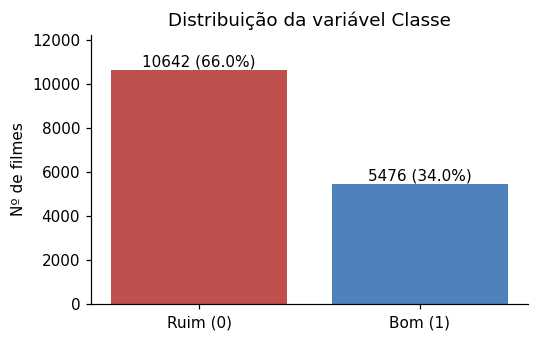

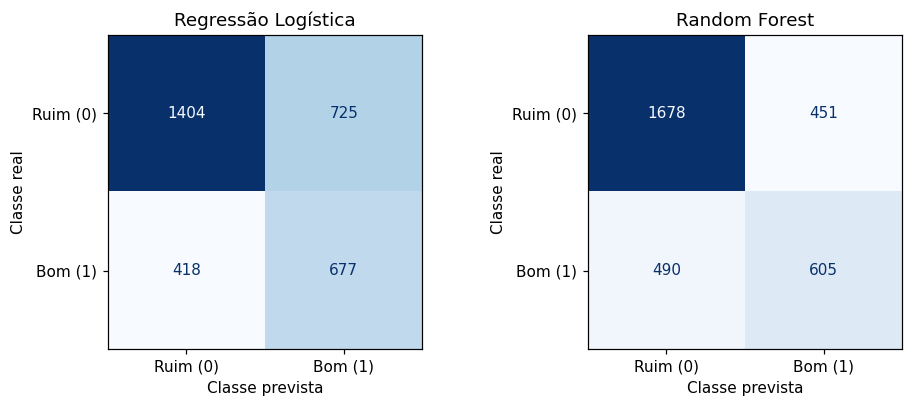

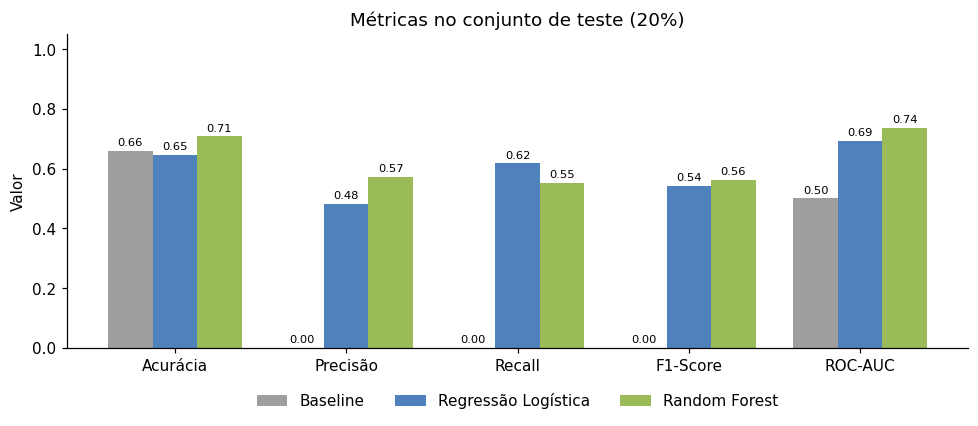

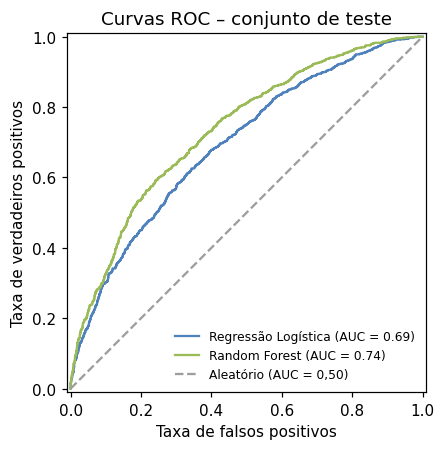

In [8]:
# Distribuição da classe
fig, ax = plt.subplots(figsize=(5, 3.2))
vc = y.value_counts().sort_index()
ax.bar(['Ruim (0)', 'Bom (1)'], vc.values, color=['#c0504d', '#4f81bd'])
for i, v in enumerate(vc.values):
    ax.text(i, v + 150, f'{v} ({v / len(y):.1%})', ha='center')
ax.set_ylabel('Nº de filmes'); ax.set_title('Distribuição da variável Classe')
ax.set_ylim(0, vc.max() * 1.15); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('figs/distribuicao_classe.png', dpi=200); plt.show()

# Matrizes de confusão
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, name in zip(axes, ['Regressão Logística', 'Random Forest']):
    ConfusionMatrixDisplay(np.array(test_results[name]['cm']),
                           display_labels=['Ruim (0)', 'Bom (1)']).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(name); ax.set_xlabel('Classe prevista'); ax.set_ylabel('Classe real')
plt.tight_layout(); plt.savefig('figs/matrizes_confusao.png', dpi=200); plt.show()

# Comparativo de métricas
names = ['Baseline (classe majoritária)', 'Regressão Logística', 'Random Forest']
labels = ['Acurácia', 'Precisão', 'Recall', 'F1-Score', 'ROC-AUC']
keys = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
cols = ['#9e9e9e', '#4f81bd', '#9bbb59']
xx = np.arange(len(keys)); w = 0.26
fig, ax = plt.subplots(figsize=(9, 4))
for i, (n, c) in enumerate(zip(names, cols)):
    vals = [test_results[n][k] for k in keys]
    b = ax.bar(xx + (i - 1) * w, vals, w, label=n.replace(' (classe majoritária)', ''), color=c)
    ax.bar_label(b, fmt='%.2f', fontsize=7.5, padding=2)
ax.set_xticks(xx); ax.set_xticklabels(labels); ax.set_ylim(0, 1.05)
ax.set_ylabel('Valor'); ax.set_title('Métricas no conjunto de teste (20%)')
ax.legend(frameon=False, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1))
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('figs/comparativo_metricas.png', dpi=200); plt.show()

# Curvas ROC
fig, ax = plt.subplots(figsize=(5, 4.2))
for n, c in zip(names[1:], cols[1:]):
    RocCurveDisplay.from_predictions(y_test, probas[n], name=n, ax=ax, color=c)
ax.plot([0, 1], [0, 1], '--', color='#9e9e9e', label='Aleatório (AUC = 0,50)')
ax.set_xlabel('Taxa de falsos positivos'); ax.set_ylabel('Taxa de verdadeiros positivos')
ax.set_title('Curvas ROC – conjunto de teste'); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig('figs/curvas_roc.png', dpi=200); plt.show()

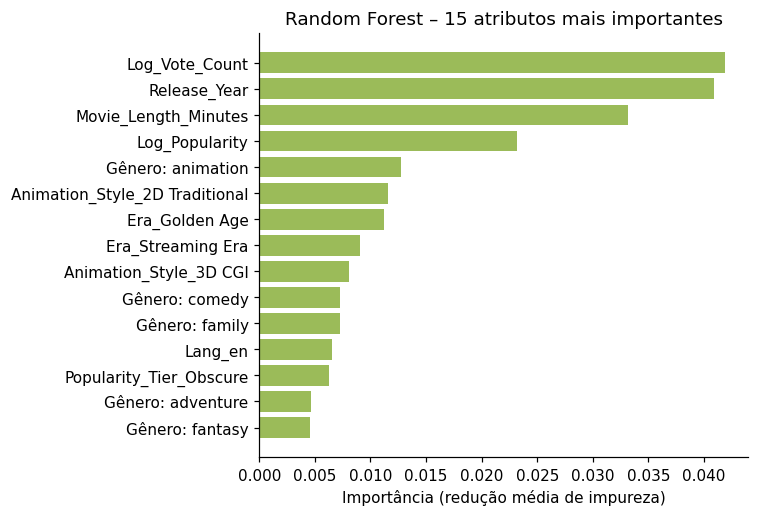

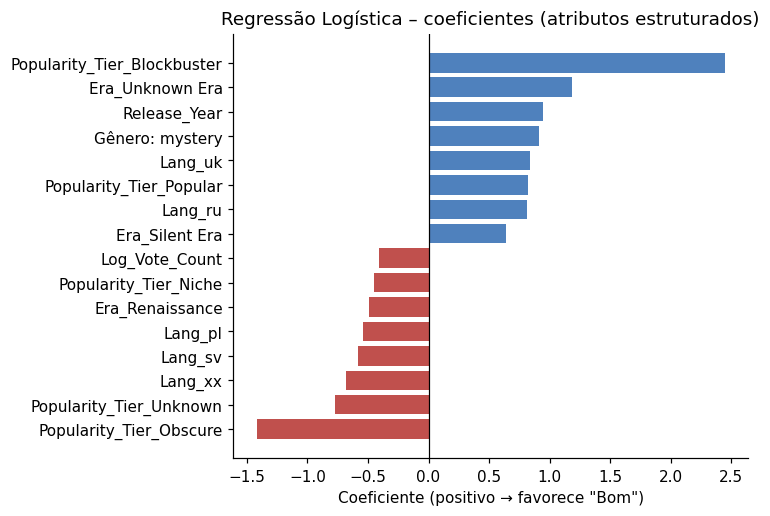

In [9]:
# Importância dos atributos (Random Forest)
rf = pipes['Random Forest']
feat_names = rf.named_steps['prep'].get_feature_names_out()
imp = pd.Series(rf.named_steps['clf'].feature_importances_, index=feat_names)
pretty = (imp.index.str.replace('num__', '').str.replace('cat__', '')
          .str.replace('genre__', 'Gênero: ').str.replace('ovw__', 'Sinopse: '))
imp.index = pretty
top = imp.sort_values(ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.barh(top.index, top.values, color='#9bbb59')
ax.set_xlabel('Importância (redução média de impureza)')
ax.set_title('Random Forest – 15 atributos mais importantes')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('figs/importancia_rf.png', dpi=200); plt.show()

# Coeficientes (Regressão Logística)
lr = pipes['Regressão Logística']
coef = pd.Series(lr.named_steps['clf'].coef_[0], index=pretty)
coef = coef[~coef.index.str.startswith('Sinopse: ')]  # atributos estruturados (mais interpretáveis)
top_lr = pd.concat([coef.nsmallest(8), coef.nlargest(8)]).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.barh(top_lr.index, top_lr.values, color=np.where(top_lr.values > 0, '#4f81bd', '#c0504d'))
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Coeficiente (positivo → favorece "Bom")')
ax.set_title('Regressão Logística – coeficientes (atributos estruturados)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('figs/coeficientes_lr.png', dpi=200); plt.show()

## 8. Exportação dos resultados

In [10]:
out = {'split': split_info, 'cv': cv_results, 'test': test_results,
       'n_features': int(len(feat_names)),
       'rf_top': top[::-1].round(4).to_dict(), 'lr_top': top_lr.round(3).to_dict()}
with open('resultados.json', 'w', encoding='utf-8') as f:
    json.dump(out, f, ensure_ascii=False, indent=2)
print('Total de atributos após transformação:', len(feat_names))

Total de atributos após transformação: 3080
